**1️⃣ Import Libraries**

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

**2️⃣ Load YouTube Dataset**

In [ ]:
channels = pd.read_excel("youtube_sna_dataset_600channels.xlsx", sheet_name="channels")
edges = pd.read_excel("youtube_sna_dataset_600channels.xlsx", sheet_name="interactions")

pd.set_option('display.expand_frame_repr', False)

print(channels)
print(edges)

    channel_name  subscribers  videos_uploaded  total_views    likes  comments  shares
0      channel_1      1693743              685    189912201  2535037    897201  302939
1      channel_2      4305572               99     27590296  3157573    536209  280835
2      channel_3      4927484             1681     63665986   812561    225421  443252
3      channel_4      2235489              707    179311837  4427136    208574  366018
4      channel_5      1571006             1349    120009784  4055655    729680  409118
..           ...          ...              ...          ...      ...       ...     ...
595  channel_596      2253728             1873     47728021  1720956     96094  230373
596  channel_597      2486195              136     27006639   556210    267541  134403
597  channel_598      4261507             1139     87659202   964263    714473  343502
598  channel_599       161775             1018     10784986  3012639    489116  430609
599  channel_600      2668867              

**3️⃣ Build Network Graph**

In [ ]:
G = nx.from_pandas_edgelist(
    edges,
    source='source_channel',
    target='target_channel'
)

print("Total Nodes:", G.number_of_nodes())
print("Total Edges:", G.number_of_edges())

Total Nodes: 600
Total Edges: 3463


**4️⃣ Calculate Centrality Measures**

In [ ]:
degree = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G)
closeness = nx.closeness_centrality(G)
eigenvector = nx.eigenvector_centrality(G, max_iter=1000)

**5️⃣ Store Results in DataFrame**

In [ ]:
centrality_df = pd.DataFrame({
    "channel": list(degree.keys()),
    "degree": list(degree.values()),
    "betweenness": list(betweenness.values()),
    "closeness": list(closeness.values()),
    "eigenvector": list(eigenvector.values())
})

print(centrality_df.head())

       channel    degree  betweenness  closeness  eigenvector
0  channel_174  0.008347     0.000599   0.307653     0.014523
1  channel_266  0.023372     0.004635   0.366810     0.052506
2  channel_343  0.025042     0.004971   0.364134     0.051409
3   channel_95  0.020033     0.002847   0.355279     0.043440
4  channel_431  0.020033     0.003114   0.349475     0.037103


**6️⃣ Calculate Influence Score**

In [ ]:
centrality_df["rank_score"] = (
    centrality_df["degree"] +
    centrality_df["betweenness"] +
    centrality_df["closeness"] +
    centrality_df["eigenvector"]
)

**7️⃣ Find Top Influencers**

In [ ]:
top_influencers = centrality_df.sort_values(
    by="rank_score",
    ascending=False
).head(10)

print(top_influencers)

         channel    degree  betweenness  closeness  eigenvector  rank_score
112  channel_560  0.036728     0.009838   0.386951     0.083636    0.517153
42   channel_387  0.036728     0.009798   0.386452     0.083794    0.516772
348  channel_528  0.035058     0.009356   0.384467     0.077823    0.506705
314  channel_439  0.035058     0.009626   0.383728     0.076805    0.505217
238  channel_503  0.031720     0.007916   0.382748     0.074242    0.496625
94    channel_73  0.033389     0.008089   0.378635     0.075672    0.495784
309  channel_171  0.031720     0.007534   0.381772     0.072657    0.493683
343  channel_464  0.031720     0.007591   0.378874     0.071699    0.489883
195   channel_59  0.035058     0.008868   0.376493     0.069305    0.489724
147  channel_433  0.028381     0.006292   0.379835     0.068338    0.482846


**8️⃣ Highlight Influencers in Network Graph**

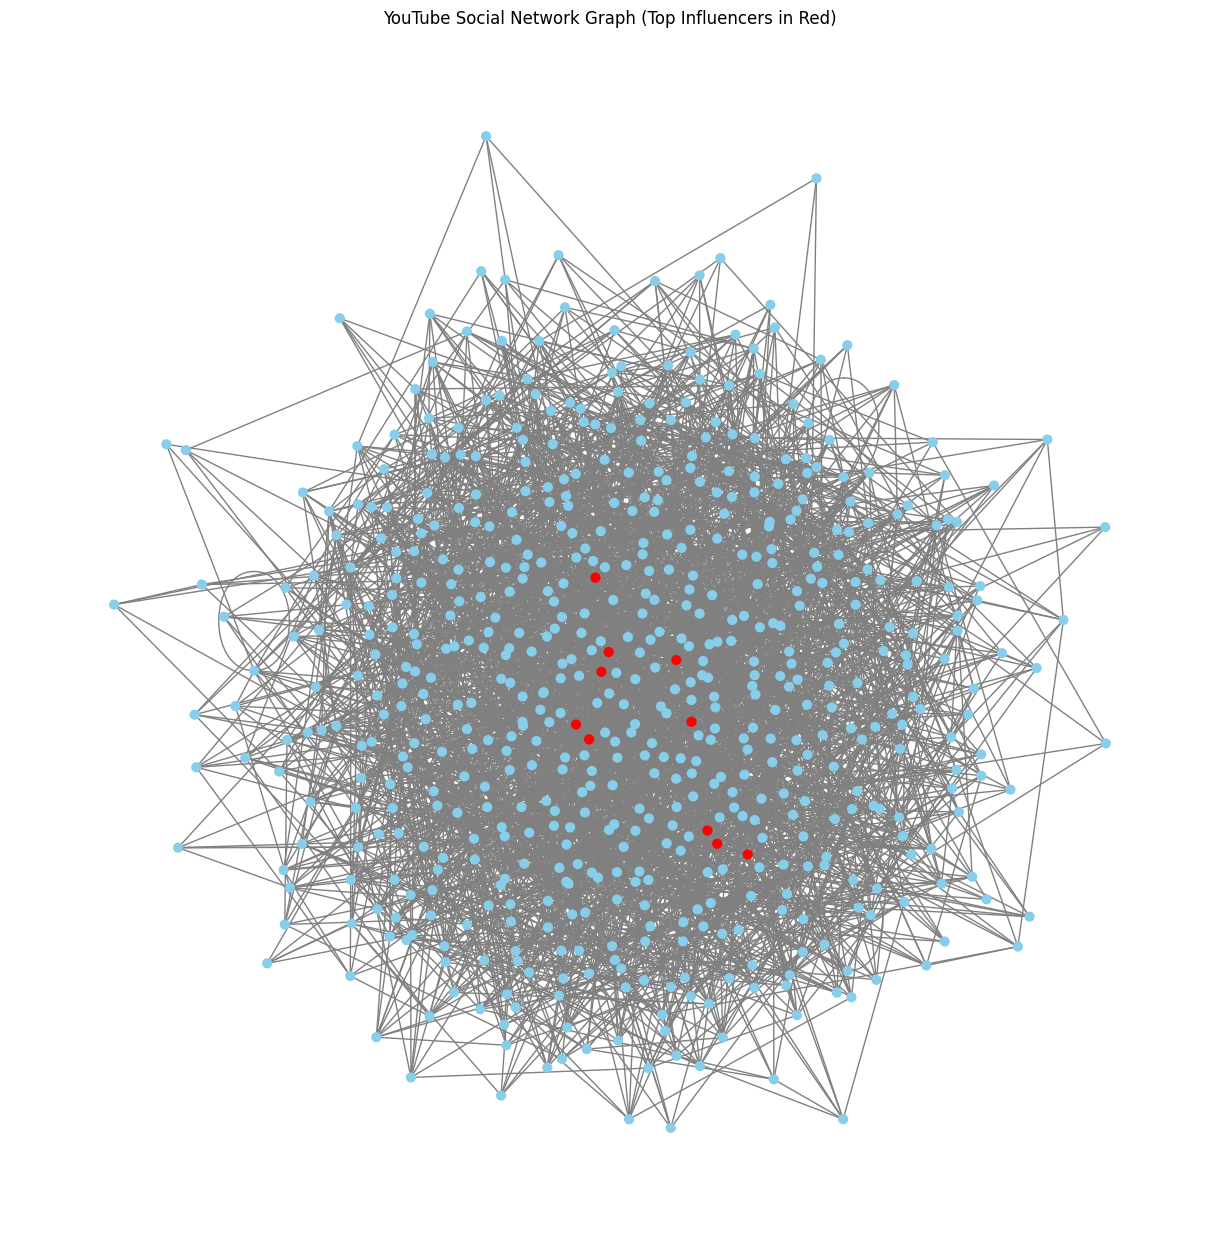

In [ ]:
top_channels = list(top_influencers["channel"])

plt.figure(figsize=(12,12))

pos = nx.spring_layout(G)

node_colors = []

for node in G.nodes():
    if node in top_channels:
        node_colors.append("red")
    else:
        node_colors.append("skyblue")

nx.draw(
    G,
    pos,
    node_size=40,
    node_color=node_colors,
    edge_color="gray",
    with_labels=False
)

plt.title("YouTube Social Network Graph (Top Influencers in Red)")
plt.show()

**9️⃣ Save Results**

In [ ]:
centrality_df.to_excel("youtube_influencer_results.xlsx", index=False)

**Feature-1: Sentiment Analysis**

In [ ]:
good_comments = [
"Great video!",
"Excellent content",
"Very helpful post",
"I really like this",
"Amazing work",
"Very informative",
"Love this content",
"Keep it up",
"This is fantastic",
"Very interesting"
]

bad_comments = [
"This is terrible",
"I don't like this",
"Waste of time",
"Very bad content",
"Not useful at all",
"Poor explanation",
"This is boring",
"Disappointing post",
"I hate this",
"Very confusing"
]

In [ ]:
import pandas as pd
import random

file = "youtube_sna_dataset_600channels.xlsx"

channels = pd.read_excel(file, sheet_name="channels")
edges = pd.read_excel(file, sheet_name="interactions")

edges["comment_text"] = ""

for i in range(len(edges)):
    if edges.loc[i,"interaction_type"] == "comment":
        edges.loc[i,"comment_text"] = random.choice(good_comments + bad_comments)

with pd.ExcelWriter("youtube_sentiment_dataset.xlsx") as writer:
    channels.to_excel(writer, sheet_name="channels", index=False)
    edges.to_excel(writer, sheet_name="interactions", index=False)

**Method: Sentiment Analysis Using TextBlob**

**Step 1: Install Library**

In [ ]:
!pip install textblob

**Step 2: Load Dataset**

In [ ]:
import pandas as pd

edges = pd.read_excel("youtube_sentiment_dataset.xlsx", sheet_name="interactions")

edges.head(10)

,source_channel,target_channel,interaction_type,comment_text
0,channel_174,channel_266,subscription,NaN
1,channel_343,channel_95,subscription,NaN
2,channel_431,channel_262,mention,NaN
3,channel_324,channel_71,mention,NaN
4,channel_420,channel_219,subscription,NaN
5,channel_594,channel_533,recommendation,NaN
6,channel_485,channel_92,comment,I hate this
7,channel_412,channel_127,collaboration,NaN
8,channel_84,channel_80,mention,NaN
9,channel_113,channel_238,subscription,NaN


**Step 3: Perform Sentiment Analysis**

In [ ]:
from textblob import TextBlob

def analyze_sentiment(text):

    if text == "" or pd.isna(text):
        return "No Comment"

    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0:
        return "Positive"
    else:
        return "Negative"


edges["predicted_sentiment"] = edges["comment_text"].apply(analyze_sentiment)

**Step 4: See Results**

In [ ]:
edges[["comment_text","predicted_sentiment"]].head(10)

,comment_text,predicted_sentiment
0,NaN,No Comment
1,NaN,No Comment
2,NaN,No Comment
3,NaN,No Comment
4,NaN,No Comment
5,NaN,No Comment
6,I hate this,Negative
7,NaN,No Comment
8,NaN,No Comment
9,NaN,No Comment


**Step 5: Count Positive vs Negative Comments**

In [ ]:
edges["predicted_sentiment"].value_counts()

,count
predicted_sentiment,
No Comment,2833
Negative,357
Positive,310


**Step 6: Visualization**

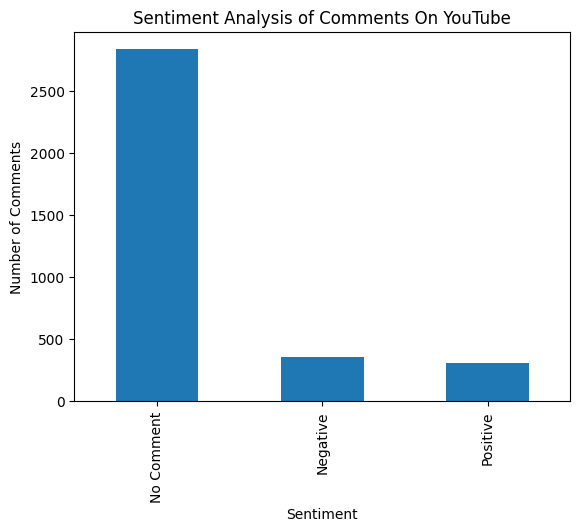

In [ ]:
import matplotlib.pyplot as plt

edges["predicted_sentiment"].value_counts().plot(kind="bar")

plt.title("Sentiment Analysis of Comments On YouTube")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")

plt.show()

**Feature-2: BOT/FAKE Account/Channel Detection**

In [ ]:
import pandas as pd

In [ ]:
# Load nodes sheet (user data)
df = pd.read_excel("youtube_sna_dataset_600channels.xlsx", sheet_name="channels")

df.head()

,channel_name,subscribers,videos_uploaded,total_views,likes,comments,shares
0,channel_1,1693743,685,189912201,2535037,897201,302939
1,channel_2,4305572,99,27590296,3157573,536209,280835
2,channel_3,4927484,1681,63665986,812561,225421,443252
3,channel_4,2235489,707,179311837,4427136,208574,366018
4,channel_5,1571006,1349,120009784,4055655,729680,409118


In [ ]:
def bot_score_youtube(row):
    score = 0

    # Rule 1: Very low subscribers
    if row['subscribers'] < 100:
        score += 1

    # Rule 2: Too many videos uploaded
    if row['videos_uploaded'] > 200:
        score += 1

    # Rule 3: Low views compared to videos
    if row['total_views'] < 1000:
        score += 1

    # Rule 4: Low engagement (likes + comments)
    if (row['likes'] + row['comments']) < 50:
        score += 1

    # Rule 5: Low network influence (if exists)
    if 'eigenvector' in row and row['eigenvector'] < 0.01:
        score += 1

    return score

In [ ]:
channels["bot_score"] = channels.apply(bot_score_youtube, axis=1)

In [ ]:
channels["account_type"] = channels["bot_score"].apply(
    lambda x: "Bot" if x >= 3 else "Real Channel"
)

In [ ]:
print(channels[["channel_name", "bot_score", "account_type"]].head(10))

  channel_name  bot_score  account_type
0    channel_1          1  Real Channel
1    channel_2          0  Real Channel
2    channel_3          1  Real Channel
3    channel_4          1  Real Channel
4    channel_5          1  Real Channel
5    channel_6          1  Real Channel
6    channel_7          1  Real Channel
7    channel_8          1  Real Channel
8    channel_9          1  Real Channel
9   channel_10          0  Real Channel


In [ ]:
print(channels["account_type"].value_counts())

account_type
Real Channel    600
Name: count, dtype: int64


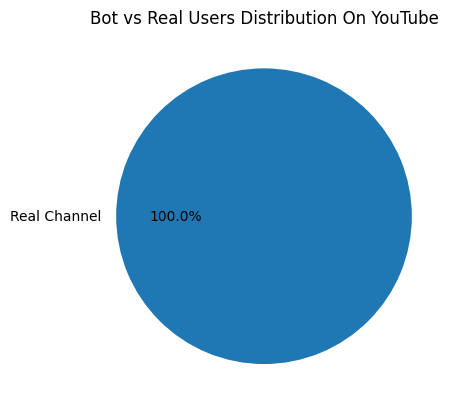

In [ ]:
import matplotlib.pyplot as plt

channels["account_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.title("Bot vs Real Users Distribution On YouTube")
plt.ylabel("")

plt.show()